# 数据可视化课堂作业：Seaborn 课堂练习（课件 p.60-63）

- **学生姓名**：沈美梓
- **学号**：17420249605674
- **课程**：数据可视化
- **作业要求**：
  根据提供的数据集 `orders.txt`，完成课件第 60 至 63 页的 Seaborn 课堂练习：
  1. **练习 1 (p.60)**：使用 `sns.relplot`，绘制各个门店 2014-2020 期间不同产品品类 (`category`) 的利润折线图。
  2. **练习 2 (p.61)**：使用 `sns.displot`，绘制 2020 年各个门店不同产品品类的利润直方图和核密度曲线。
  3. **练习 3 (p.62)**：使用 `sns.catplot`，绘制 2020 年各个门店不同产品品类的利润散点图、箱型图、条形图。
  4. **练习 4 (p.63)**：使用 `sns.lmplot`，绘制 2020 年各个产品类别的销量和利润关系的拟合曲线。

## 一、运行环境配置与字体设置

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

# 1. 采用课件中的 Seaborn 默认主题风格（灰底白网格，与课件幻灯片视觉一致）
sns.set_theme(style='darkgrid')

# 2. 跨平台中文字体配置（兼容 Mac / Windows / Linux）并正常显示负号
mpl.rcParams['font.sans-serif'] = ['Arial Unicode MS', 'Hiragino Sans GB', 'PingFang SC', 'Songti SC', 'SimHei', 'Microsoft YaHei', 'sans-serif']
mpl.rcParams['axes.unicode_minus'] = False

## 二、数据读取与预处理

In [2]:
# 读取订单数据集 orders.txt
df = pd.read_csv('orders.txt')

print(f"数据集总维度：{df.shape[0]} 行, {df.shape[1]} 列")
print(f"年份范围：{df['dt'].min()} ~ {df['dt'].max()}")
print(f"门店列表：{df['store_name'].unique().tolist()}")
print(f"产品品类：{df['category'].unique().tolist()}")

# 筛选 2020 年数据子集
df_2020 = df[df['dt'] == 2020].copy()
print(f"2020年数据量：{df_2020.shape[0]} 行")

df[['order_id', 'order_date', 'store_name', 'category', 'sales', 'profit', 'dt']].head()

数据集总维度：19490 行, 25 列
年份范围：2014 ~ 2020
门店列表：['定远店', '人民店', '杨店店', '庐江店', '金寨店', '众兴店', '海恒店', '临泉店', '燎原店']
产品品类：['办公用品', '家具', '技术']
2020年数据量：1510 行


,order_id,order_date,store_name,category,sales,profit,dt
0,CN-2014-100007,2014/1/1,定远店,办公用品,1622.600,291.34,2014
1,CN-2014-100001,2014/1/1,人民店,办公用品,919.100,144.24,2014
2,CN-2014-100002,2014/1/1,杨店店,办公用品,284.480,47.53,2014
3,CN-2014-100003,2014/1/1,庐江店,办公用品,920.976,-41.49,2014
4,CN-2014-100004,2014/1/1,金寨店,办公用品,95.088,-8.05,2014


## 三、练习 1：使用 sns.relplot 绘制各门店 2014-2020 利润折线图（课件 p.60）

**题目要求：**
根据提供的数据集 `orders.txt`，使用 `sns.relplot`，绘制各个门店 2014-2020 期间，不同产品品类 (`category`) 的利润折线图。

**实现细节与参数映射：**
- 函数：`sns.relplot(..., kind='line')`
- 自变量与因变量：横轴为年份 (`dt`)，纵轴为利润 (`profit`)
- 分组色彩：以产品品类 `category` 进行颜色区分 (`hue='category'`)
- 分面维度：以门店 `store_name` 建立子图网格，每行 3 个子图 (`col='store_name'`, `col_wrap=3`)
- 图形美化：添加总标题 `2014-2020门店各品类利润折线图`，横纵坐标轴分别标注 `年份` 与 `利润`

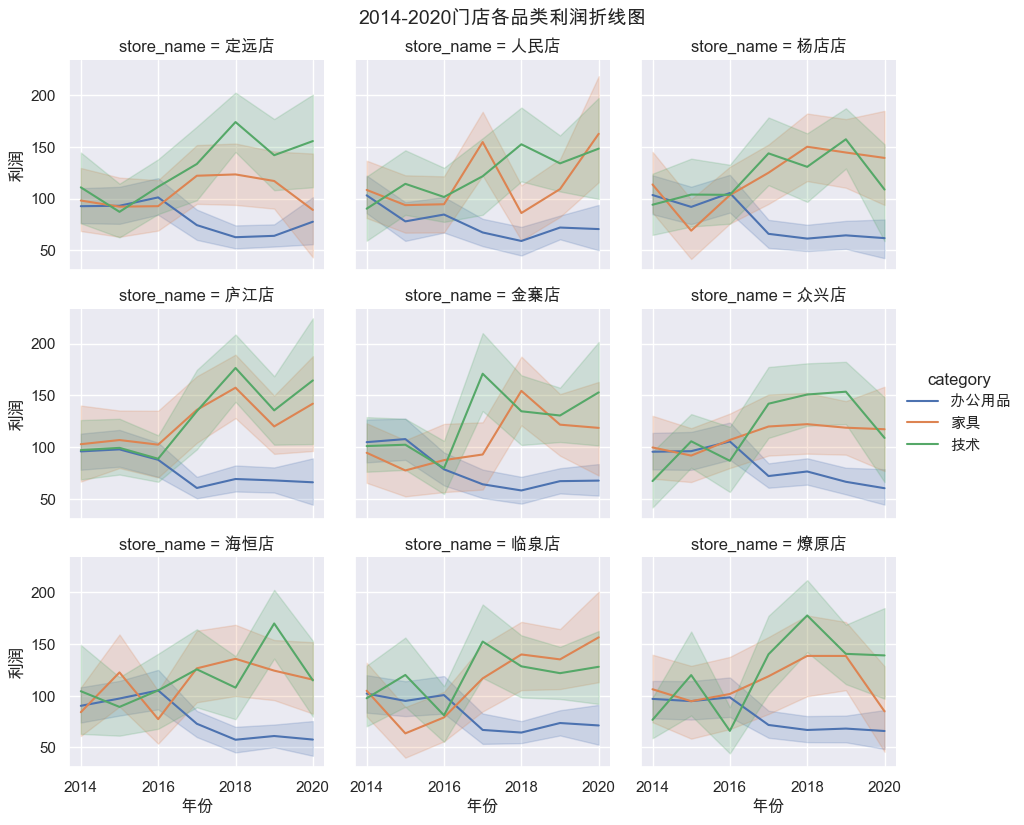

In [3]:
# 绘制 2014-2020 期间各门店不同产品品类的利润折线图
g1 = sns.relplot(
    data=df,
    x='dt',
    y='profit',
    hue='category',
    col='store_name',
    col_wrap=3,
    kind='line',
    height=2.8,
    aspect=1.1
)

# 调整总标题与坐标轴标签（与课件 p.60 原图完全对齐）
g1.fig.subplots_adjust(top=0.92)
g1.fig.suptitle('2014-2020门店各品类利润折线图', fontsize=14, y=0.98)
g1.set_axis_labels('年份', '利润')

plt.show()

## 四、练习 2：使用 sns.displot 绘制 2020 年各门店不同品类的利润直方图和核密度曲线（课件 p.61）

**题目要求：**
根据提供的数据集 `orders.txt`，使用 `sns.displot`，绘制 2020 年各个门店不同产品品类的利润直方图和核密度曲线。

**实现细节与参数映射：**
- 数据源：2020 年数据子集 (`df_2020`)
- 函数：`sns.displot(..., kind='hist', kde=True)`
- 变量：横轴为订单利润额 (`x='profit'`)，纵轴为频数计数 (`count`)
- 分组与分面：`hue='category'`，以 `col='store_name'`, `col_wrap=3` 构建 3×3 门店子图网格
- 图形美化：总标题标注 `2020年上半年利润额的频数分布图`，坐标轴标注 `利润额` 与 `计数`

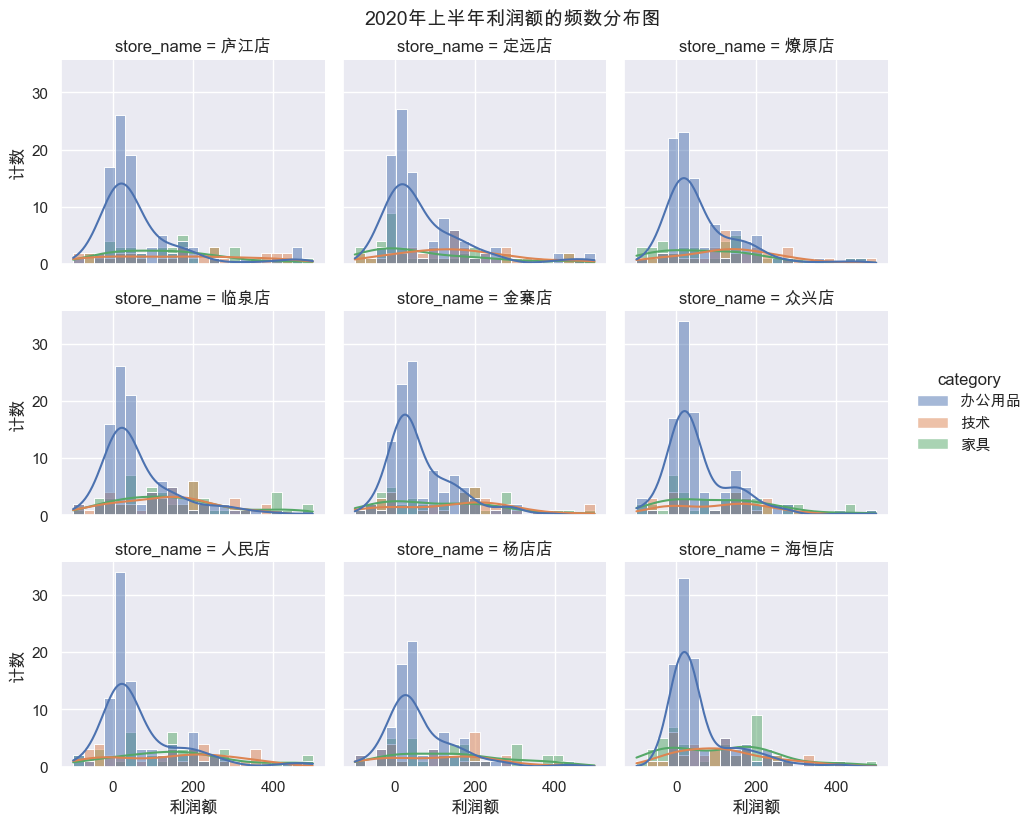

In [4]:
# 绘制 2020 年各门店不同产品品类的利润直方图和核密度曲线
g2 = sns.displot(
    data=df_2020,
    x='profit',
    hue='category',
    col='store_name',
    col_wrap=3,
    kde=True,
    height=2.8,
    aspect=1.1
)

# 调整总标题与坐标轴标签（对应课件 p.61 原图标题）
g2.fig.subplots_adjust(top=0.92)
g2.fig.suptitle('2020年上半年利润额的频数分布图', fontsize=14, y=0.98)
g2.set_axis_labels('利润额', '计数')

plt.show()

## 五、练习 3：使用 sns.catplot 绘制 2020 年各门店不同品类的分类图（课件 p.62）

**题目要求：**
根据提供的数据集 `orders.txt`，使用 `sns.catplot`，绘制 2020 年各个门店不同产品品类的利润散点图、箱型图、条形图。

课件第 62 页展示了分类变量可视化的三种核心图表形式：
1. **分类散点图 (Strip Plot)**：`kind='strip'`，展示各门店每笔订单的实际散点位置与聚集密集区
2. **分类条形图 (Bar Plot)**：`kind='bar'`，展示各门店不同品类利润均值并附带 95% 置信区间误差棒
3. **分类箱型图 (Box Plot)**：`kind='box'`，展示各门店不同品类利润的中位数、四分位距及离群异常值

### 3.1 绘制分类散点图 (kind='strip')

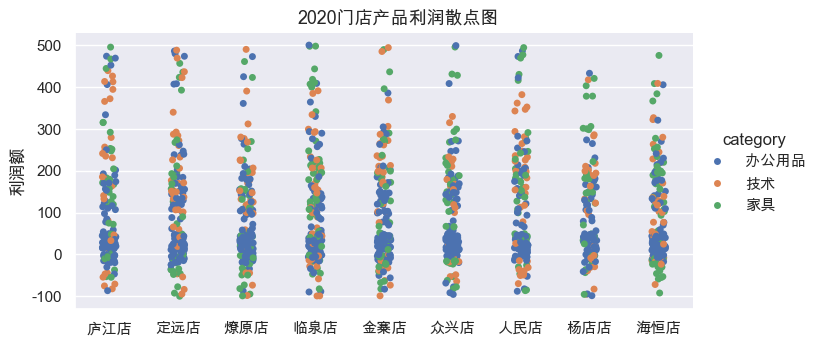

In [5]:
# 3.1 绘制 2020 门店产品利润散点图
g3_strip = sns.catplot(
    data=df_2020,
    x='store_name',
    y='profit',
    hue='category',
    kind='strip',
    height=3.8,
    aspect=1.9
)

g3_strip.fig.subplots_adjust(top=0.90)
g3_strip.fig.suptitle('2020门店产品利润散点图', fontsize=13, y=0.96)
g3_strip.set_axis_labels('', '利润额')

plt.show()

### 3.2 绘制分类条形图 (kind='bar')

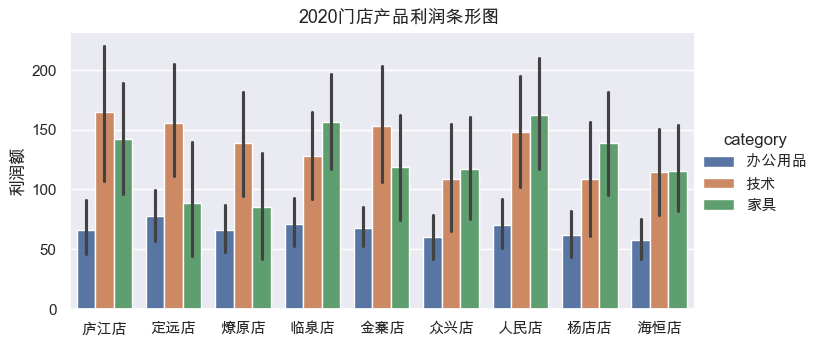

In [6]:
# 3.2 绘制 2020 门店产品利润条形图
g3_bar = sns.catplot(
    data=df_2020,
    x='store_name',
    y='profit',
    hue='category',
    kind='bar',
    height=3.8,
    aspect=1.9
)

g3_bar.fig.subplots_adjust(top=0.90)
g3_bar.fig.suptitle('2020门店产品利润条形图', fontsize=13, y=0.96)
g3_bar.set_axis_labels('', '利润额')

plt.show()

### 3.3 绘制分类箱型图 (kind='box')

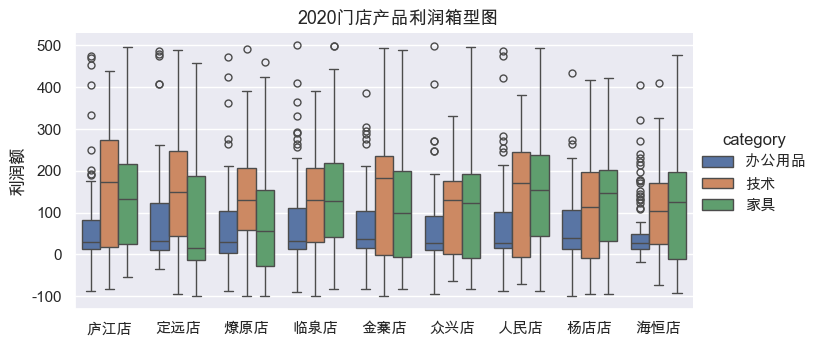

In [7]:
# 3.3 绘制 2020 门店产品利润箱型图
g3_box = sns.catplot(
    data=df_2020,
    x='store_name',
    y='profit',
    hue='category',
    kind='box',
    height=3.8,
    aspect=1.9
)

g3_box.fig.subplots_adjust(top=0.90)
g3_box.fig.suptitle('2020门店产品利润箱型图', fontsize=13, y=0.96)
g3_box.set_axis_labels('', '利润额')

plt.show()

## 六、练习 4：使用 sns.lmplot 绘制 2020 年产品类别销量与利润关系的拟合曲线（课件 p.63）

**题目要求：**
根据提供的数据集 `orders.txt`，使用 `sns.lmplot`，绘制 2020 年各个产品类别的销量和利润关系的拟合曲线。

**实现细节与参数映射：**
- 变量映射：横轴销量 `sales`，纵轴利润 `profit`，品类分组 `hue='category'`
- 拟合模型阶数：课件 p.63 中的拟合曲线呈现向上的抛物线形态，采用二次多项式拟合 (`order=2`)
- 图形美化：总标题标注 `2020销量和利润拟合曲线`，坐标轴标注 `销量` 与 `利润额`

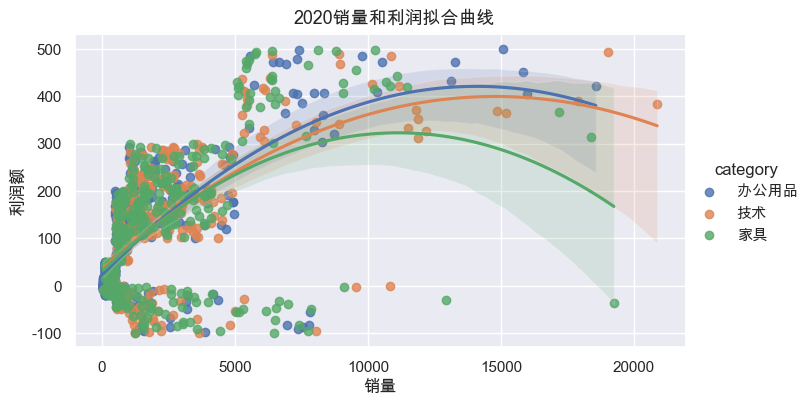

In [8]:
# 绘制 2020 销量和利润二次多项式拟合曲线 (对应课件 p.63)
g4 = sns.lmplot(
    data=df_2020,
    x='sales',
    y='profit',
    hue='category',
    order=2,
    height=4.2,
    aspect=1.7
)

g4.fig.subplots_adjust(top=0.90)
g4.fig.suptitle('2020销量和利润拟合曲线', fontsize=13, y=0.96)
g4.set_axis_labels('销量', '利润额')

plt.show()

### 附：一次线性拟合与二次多项式拟合对比分析

为了更深入探讨订单销售规模与盈利水平的边际变动趋势，对比展示一次线性回归 (`order=1`) 与二次多项式拟合 (`order=2`) 的拟合差异。

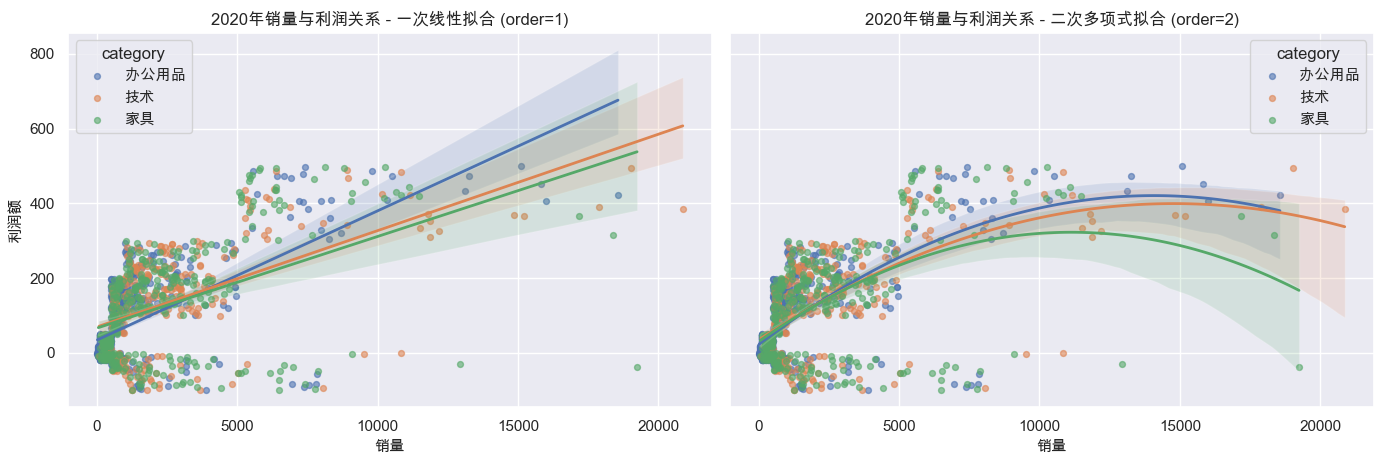

In [9]:
# 对比展示：左图为一次线性回归 (order=1)，右图为二次多项式拟合 (order=2)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)

categories = df_2020['category'].unique()

for i, (order, title_suffix) in enumerate([(1, '一次线性拟合 (order=1)'), (2, '二次多项式拟合 (order=2)')]):
    ax = axes[i]
    for cat in categories:
        subset = df_2020[df_2020['category'] == cat]
        sns.regplot(
            data=subset,
            x='sales',
            y='profit',
            order=order,
            label=cat,
            ax=ax,
            scatter_kws={'alpha': 0.6, 's': 18},
            line_kws={'linewidth': 2}
        )
    ax.set_title(f'2020年销量与利润关系 - {title_suffix}', fontsize=12)
    ax.set_xlabel('销量', fontsize=11)
    ax.set_ylabel('利润额' if i == 0 else '', fontsize=11)
    ax.legend(title='category')

plt.tight_layout()
plt.show()

## 七、可视化分析总结与商业洞察

1. **品类与门店利润趋势 (relplot 折线图)**：
   - 2014 至 2020 年期间，各门店中**技术类**产品的单笔订单平均利润普遍位列第一，但波动范围相对较广（置信区间带较宽）；
   - **办公用品**的单笔利润表现高度稳健，在各门店长年稳定在 50~100 元区间，年际波动较小；
   - **家具类**产品在大部分门店在 2016-2018 年期间呈现明显的利润爬坡与增长趋势。

2. **利润分布与偏态特征 (displot 直方图与核密度曲线)**：
   - 2020 年各门店的订单利润均呈现典型的**右偏（正偏态）分布**；
   - 绝大部分订单集中在 0~100 元的低中利润区间，特别是办公用品在低额利润处形成极高尖峰；
   - 尾部向右延伸至 500 元高利润区，同时左侧存在少量负利润订单（可能源于大额退货或高折扣让利）。

3. **分类对比特征 (catplot 散点图、条形图与箱型图)**：
   - **散点图**直观展示了数据订单密集带，低利润区散点重叠紧密，中高利润区散点较为分散；
   - **条形图**（均值估计）突显了技术与家具类产品平均收益优势显著，各门店品类排序保持较高一致性；
   - **箱型图**揭示了技术类与家具类的四分位距 (IQR) 明显大于办公用品，体现其更高的收益弹性和离散度。

4. **销量与利润关系建模 (lmplot 回归拟合)**：
   - 二次多项式拟合曲线揭示了销售额与利润额之间呈现**边际递减**的抛物线规律；
   - 在中低销量区间，利润随着销售额扩大呈现强劲上升；当销售额进一步扩大进入超大订单区间时，由于批量折扣幅度加大、配送与安装综合成本上升等原因，单笔边际利润增速有所放缓，表现为二次曲线的曲度下弯。